# Agreements — What do the raters agree on?

A **triple** connects a subject, a predicate, and an object: for example, “Paris — located in — France”. Raters a1 and a2 marked each criterion as **True = correct** or **False = incorrect**. A blank cell is a missing rating, not a rejection.

| Criterion | What does “correct” mean? | Where is the proposed correction? |
|---|---|---|
| Label (G) | Does the name match the Wikidata entity? | No dedicated column. |
| Entity (H) | Is the chosen entity appropriate? | I: proposed entity. |
| Predicate (J) | Is the chosen relation appropriate? | K: proposed predicate. |
| Direction (L) | Are subject and object in the right order? | M: proposed direction. |
| Fidelity to the text (N) | Does the triple express what the source text says? | O: comments. |

**The adjacent column contains a rater proposal, not a verified answer.** Column P (`rdf_final`) contains the complete final graph. The individual-triple corrected-RDF column was removed. Workbook headers and original evidence retain their source language.

The inputs retain the earlier a1 adjustment: in 296 rows, G=True led to J and L being set to True. Results describe these adjusted ratings, not a new independent annotation round.

We separate agreement on judgments, error diagnoses, and graph content. See [Disagreements.ipynb](Disagreements.ipynb) for competing corrections.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'ExamSource.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook from the KGTestBench repository.')
sys.path.insert(0, str(ROOT/'ExamReview'))
import review_helpers as review
import rdf_comparison as rdf
import export_disagreements as export

INPUTS = {r: ROOT/'data/inter-rater-reliability'/f'{r}-rdf.xlsx' for r in ['a1','a2']}
SHEET = 'resultado_template_processado'
KEY = ['Identifier', 'tripla_original']
LABELS = {'label_corresponde_wikidata':'Label', 'entidade_correta':'Entity',
          'predicado_correto':'Predicate', 'direcao_relacao_correta':'Direction',
          'fidelidade_semantica':'Fidelity to the text'}
SUBSTANTIVE = {k:v for k,v in LABELS.items() if k != 'label_corresponde_wikidata'}
EXPECTED_COLUMNS = ['Identifier','Texto_Original','relacao_traduzida','RDF_Original',
    'tripla_original','posicao_no_texto','label_corresponde_wikidata','entidade_correta',
    'entidades_adequadas PREENCHER SE INCORRETO','predicado_correto',
    'predicados_adequados PREENCHER SE INCORRETO','direcao_relacao_correta',
    'direcao_relacoes_adequada PREENCHER SE INCORRETO','fidelidade_semantica','observacao','rdf_final']
hashes = {r: review.file_sha256(p) for r,p in INPUTS.items()}
for path in INPUTS.values():
    if pd.read_excel(path, sheet_name=SHEET, nrows=0).columns.tolist() != EXPECTED_COLUMNS:
        raise ValueError(f'{path.name}: the 16 column names or their order differ from the expected schema.')
loaded = {r:review.load_review(p,SHEET,KEY,list(LABELS)) for r,p in INPUTS.items()}
paired = review.align_reviews(loaded['a1'][0],loaded['a2'][0],KEY)
common = review.shared_items(paired,KEY)
relationships = common.loc[common.item_type=='relationship'].copy()
label_items = common.loc[common.item_type=='label'].copy()
whole = review.whole_triple_agreement(relationships,list(SUBSTANTIVE))
plt.rcParams.update({'font.size':11,'figure.dpi':120})
pd.set_option('display.max_colwidth',160)
COLORS = ['#285f91','#bd7225','#777777','#8765a3','#57836a']

def table(frame):
    display(frame.style.hide(axis='index').format(precision=3,na_rep='undefined'))

def bars(names, values, title, xlabel='Triples (count)', percent=False):
    fig, ax = plt.subplots(figsize=(10,max(3,len(names)*.55)),layout='constrained')
    values = np.asarray(values,dtype=float)
    ax.barh(list(names),values,color=COLORS[0])
    for i,v in enumerate(values):
        if np.isfinite(v): ax.text(v+.7,i,f'{v:.1f}%' if percent else f'{v:g}',va='center')
    finite = values[np.isfinite(values)]
    ax.set(xlabel=xlabel,title=title,xlim=(0,112 if percent else max(1,max(finite,default=0))*1.2))
    ax.invert_yaxis()
    plt.show()

def stacked(frame, columns, names, title):
    fig, ax = plt.subplots(figsize=(11,max(4,len(frame)*.6)),layout='constrained')
    left = np.zeros(len(frame))
    for col,name,color in zip(columns,names,COLORS):
        counts = frame[col].to_numpy(dtype=int)
        ax.barh(frame.index.astype(str),counts,left=left,label=name,color=color)
        for i,v in enumerate(counts):
            if v >= 4: ax.text(left[i]+v/2,i,str(v),ha='center',va='center',color='white',fontsize=10)
        left += counts
    ax.set(title=title,xlabel='Triples with both ratings (count)')
    ax.legend(loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2)
    plt.show()

display(Markdown(f"**Inputs:** {len(common)} paired items: {len(label_items)} labels and {len(relationships)} relationships. {(paired['_merge']!='both').sum()} unmatched items. Both workbooks have the same 16 columns."))

**Inputs:** 592 paired items: 297 labels and 295 relationships. 0 unmatched items. Both workbooks have the same 16 columns.

## 1. Do they agree that it is correct or incorrect?

The bars distinguish four outcomes: both approve, both reject, only a1 approves, and only a2 approves.
**Rejecting together is also agreement**, but only on that criterion.
The label criterion uses label triples; the other four criteria use relationship triples. These are different populations.

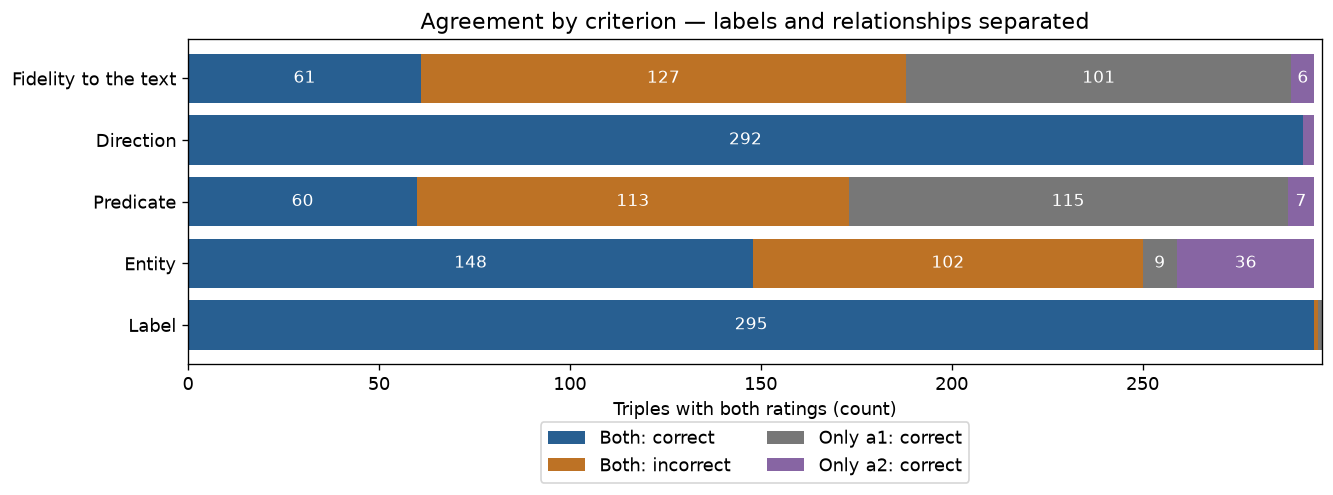

**Answer:**

- **Label:** both approve 295 and both reject 1; they disagree on 1 of 297 complete pairs.
- **Entity:** both approve 148 and both reject 102; they disagree on 45 of 295 complete pairs.
- **Predicate:** both approve 60 and both reject 113; they disagree on 122 of 295 complete pairs.
- **Direction:** both approve 292 and both reject 0; they disagree on 3 of 295 complete pairs.
- **Fidelity to the text:** both approve 61 and both reject 127; they disagree on 107 of 295 complete pairs.

In [2]:
frames = {c:label_items if c=='label_corresponde_wikidata' else relationships for c in LABELS}
category = pd.DataFrame([review.category_agreement(frames[c],c,name) for c,name in LABELS.items()])
stacked(category.set_index('criterion'),
        ['both_correct','both_incorrect','a1_correct_a2_incorrect','a1_incorrect_a2_correct'],
        ['Both: correct','Both: incorrect','Only a1: correct','Only a2: correct'],
        'Agreement by criterion — labels and relationships separated')
display(Markdown("**Answer:**\n\n"+"\n".join(f"- **{r.criterion}:** both approve {r.both_correct} and both reject {r.both_incorrect}; they disagree on {r.a1_correct_a2_incorrect+r.a1_incorrect_a2_correct} of {r.n_pairs} complete pairs." for r in category.itertuples())))

## 2. Which metrics should I use, and how do they work?

| Metric | How it works | What to use it for |
|---|---|---|
| Observed agreement ($A_o$) | (Both approve + both reject) / complete pairs. | Describe how often the raters gave the same answer. It does not adjust for chance. |
| Cohen kappa ($\kappa$) | Subtracts expected agreement based on **each rater's own** category frequencies. | Assess agreement between two raters on categories such as correct/incorrect. |
| Scott pi ($\pi$) | Uses **pooled category frequencies** to estimate expected agreement. | Assess agreement under a shared-frequency assumption; compare with kappa. |
| Coverage | Complete pairs / eligible items. | Check how much of the dataset contributes to each metric. |

For kappa and pi, **1** means perfect agreement, **0** means agreement equal to the chance model, and **negative values** mean agreement below that expectation. They are not accuracy percentages.
When expected agreement is 1, the coefficient is **undefined**, even if observed agreement is 100%.

**Why can high agreement coexist with low kappa?** If almost every answer is “incorrect”, agreement on that category is already highly expected. Read the coefficients alongside the approval/rejection counts and approval rates below. We do not assign automatic “good/bad” thresholds.

<details><summary>Formulas and references</summary>

Let $p_1$ and $p_2$ be the approval proportions in the same complete pairs:

$E_\kappa=p_1p_2+(1-p_1)(1-p_2)$; $p=(p_1+p_2)/2$; $E_\pi=p^2+(1-p)^2$.

Both coefficients use $(A_o-E)/(1-E)$.
References: [Cohen definition and implementation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.cohen_kappa_score.html) and [Scott (1955)](https://doi.org/10.1086/266577).

</details>

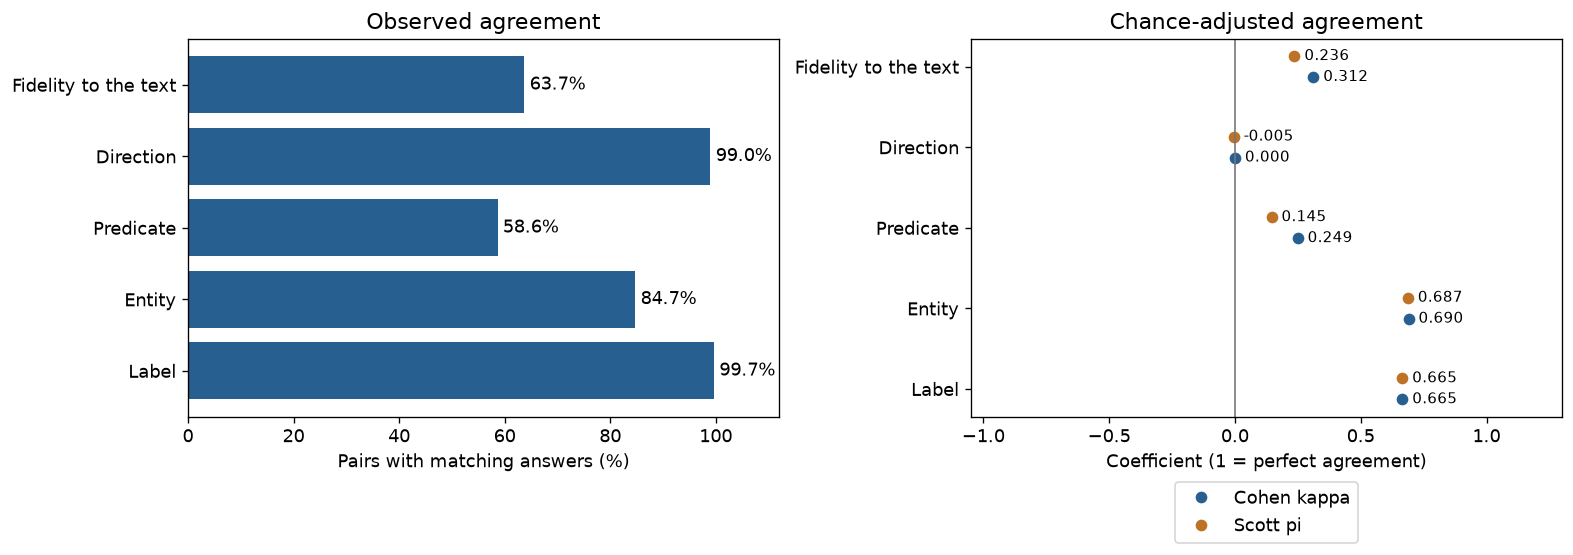

Criterion,Pairs,Coverage (%),Agreement (%),Kappa,Scott pi,a1 approves (%),a2 approves (%)
Label,297,100.000,99.663,0.665,0.665,99.663,99.327
Entity,295,100.000,84.746,0.690,0.687,53.220,62.373
Predicate,295,100.000,58.644,0.249,0.145,59.322,22.712
Direction,295,100.000,98.983,0.000,-0.005,98.983,100.000
Fidelity to the text,295,100.000,63.729,0.312,0.236,54.915,22.712


**Answer:** for predicates, observed agreement is 58.6%, kappa=0.249, and pi=0.145. a1 approves 59.3% and a2 22.7% of the same pairs. Use observed agreement to describe matching answers and the coefficients to assess agreement beyond the chance model. None of these measures identifies which rater is right.

In [3]:
records=[]
for c,name in LABELS.items():
    frame=frames[c]
    row=review.metrics(frame,c,name)
    a,b=review.complete_pairs(*review.rating_columns(frame,c))
    row['scott_pi']=review.scott_pi(a,b)
    records.append(row)
metric_summary=pd.DataFrame(records)
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
y=np.arange(len(metric_summary))
axes[0].barh(y,metric_summary.agreement_pct,color=COLORS[0])
for i,v in enumerate(metric_summary.agreement_pct): axes[0].text(v+1,i,f'{v:.1f}%',va='center')
axes[0].set(yticks=y,yticklabels=metric_summary.criterion,xlim=(0,112),title='Observed agreement',xlabel='Pairs with matching answers (%)')
for offset,col,label,color in [(-.13,'kappa_cohen','Cohen kappa',COLORS[0]),(.13,'scott_pi','Scott pi',COLORS[1])]:
    for i,v in enumerate(metric_summary[col]):
        if np.isfinite(v):
            axes[1].plot(v,i+offset,'o',color=color,label=label if i==0 else None)
            axes[1].annotate(f'{v:.3f}',(v,i+offset),xytext=(6,0),textcoords='offset points',va='center',fontsize=9)
        else: axes[1].text(-.95,i+offset,f'{label}: undefined',fontsize=9)
axes[1].axvline(0,color='#777777',lw=1)
axes[1].set(yticks=y,yticklabels=metric_summary.criterion,xlim=(-1.05,1.3),title='Chance-adjusted agreement',xlabel='Coefficient (1 = perfect agreement)')
axes[1].legend(loc='upper center',bbox_to_anchor=(.5,-.15))
plt.show()
table(metric_summary[['criterion','n_pairs','coverage_pct','agreement_pct','kappa_cohen','scott_pi',
                      'positive_a1_pct','positive_a2_pct']].rename(columns={
    'criterion':'Criterion','n_pairs':'Pairs','coverage_pct':'Coverage (%)','agreement_pct':'Agreement (%)',
    'kappa_cohen':'Kappa','scott_pi':'Scott pi','positive_a1_pct':'a1 approves (%)','positive_a2_pct':'a2 approves (%)'}))
r=metric_summary.loc[metric_summary.criterion=='Predicate'].iloc[0]
display(Markdown(f"**Answer:** for predicates, observed agreement is {r.agreement_pct:.1f}%, kappa={r.kappa_cohen:.3f}, and pi={r.scott_pi:.3f}. a1 approves {r.positive_a1_pct:.1f}% and a2 {r.positive_a2_pct:.1f}% of the same pairs. Use observed agreement to describe matching answers and the coefficients to assess agreement beyond the chance model. None of these measures identifies which rater is right."))

## 3. Do they consider the whole triple correct?

A relationship is fully approved only when entity, predicate, direction, and fidelity are all True.
This comparison requires all eight ratings: four from each rater.
**Both reject** means each rater found at least one error. They may still disagree about the error or its correction.

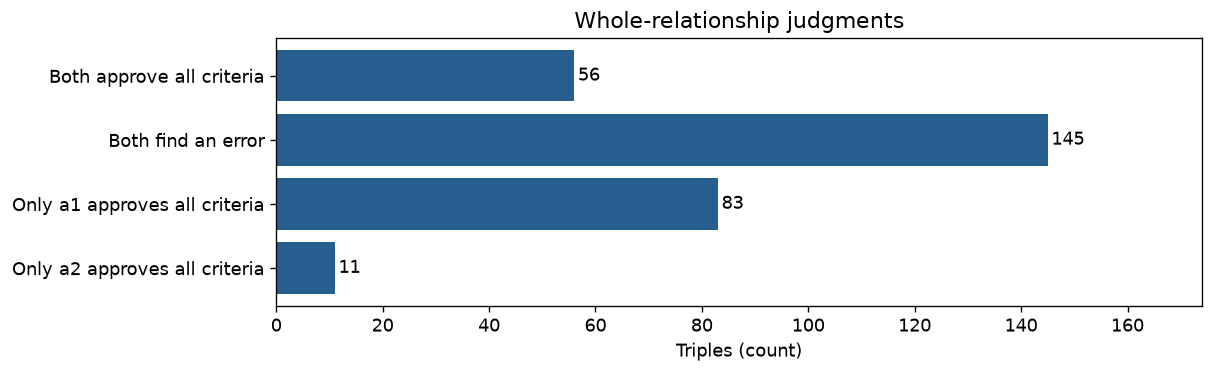

**Answer:** both approve 56 relationships and reject 145. Only one approves in 94 cases. This covers 295 of 295 relationships; 0 were excluded for missing ratings.

In [4]:
outcomes={'both_correct':'Both approve all criteria','both_incorrect':'Both find an error',
          'a1_correct_only':'Only a1 approves all criteria','a2_correct_only':'Only a2 approves all criteria'}
counts=whole[list(outcomes)].sum()
bars(list(outcomes.values()),counts,'Whole-relationship judgments')
display(Markdown(f"**Answer:** both approve {int(counts.both_correct)} relationships and reject {int(counts.both_incorrect)}. Only one approves in {int(counts.a1_correct_only+counts.a2_correct_only)} cases. This covers {len(whole)} of {len(relationships)} relationships; {len(relationships)-len(whole)} were excluded for missing ratings."))

## 4. When both reject, do they agree on the error?

The first chart shows the criteria both rejected. One triple can have several errors, so the counts overlap.
The second separates identical diagnoses, partly shared diagnoses, and diagnoses with no error in common.

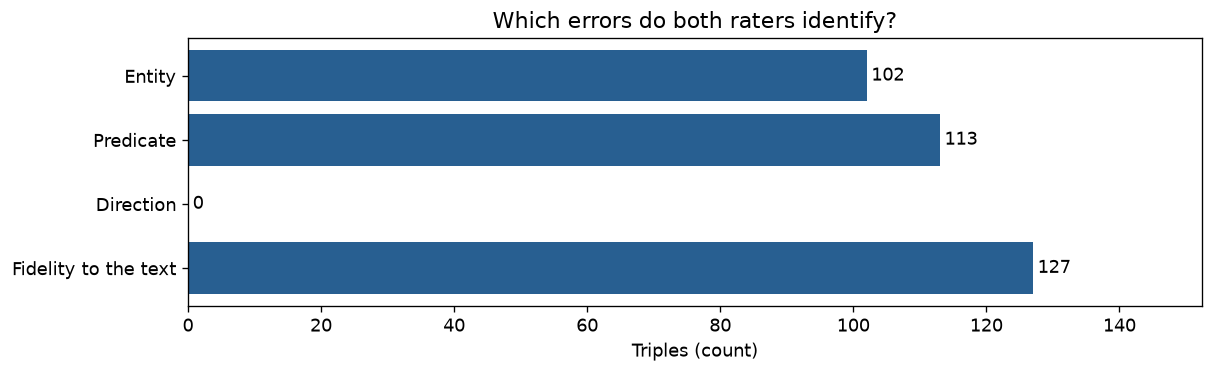

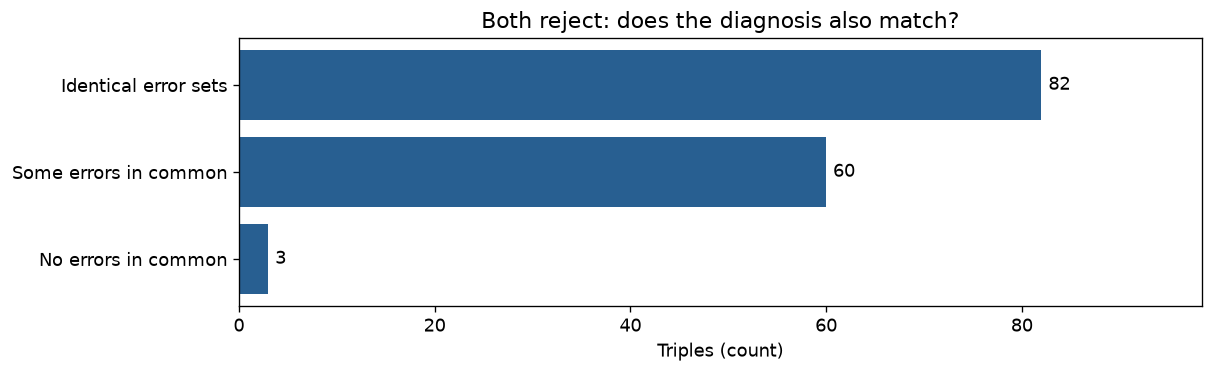

**Answer:** among 145 relationships rejected by both, 82 have identical error sets, 60 have some shared errors, and 3 have none in common. The same diagnosis does not guarantee the same correction: see Disagreements.

In [5]:
joint=review.joint_error_details(relationships,SUBSTANTIVE)
errors=review.joint_error_summary(joint,SUBSTANTIVE)
same=int(joint.same_error_set.sum())
partial=int((joint.shared_error_count.gt(0)&~joint.same_error_set).sum())
none=int(joint.shared_error_count.eq(0).sum())
bars(errors.criterion,errors.both_flag_error,'Which errors do both raters identify?')
bars(['Identical error sets','Some errors in common','No errors in common'],[same,partial,none],
     'Both reject: does the diagnosis also match?')
display(Markdown(f"**Answer:** among {len(joint)} relationships rejected by both, {same} have identical error sets, {partial} have some shared errors, and {none} have none in common. The same diagnosis does not guarantee the same correction: see Disagreements."))

## 5. Does agreement vary by source group?

Each `Identifier` is a source group. Agreement here includes both joint approval and joint rejection of the whole relationship triple.
Counts show group size; small groups should not be treated as reliable rankings.

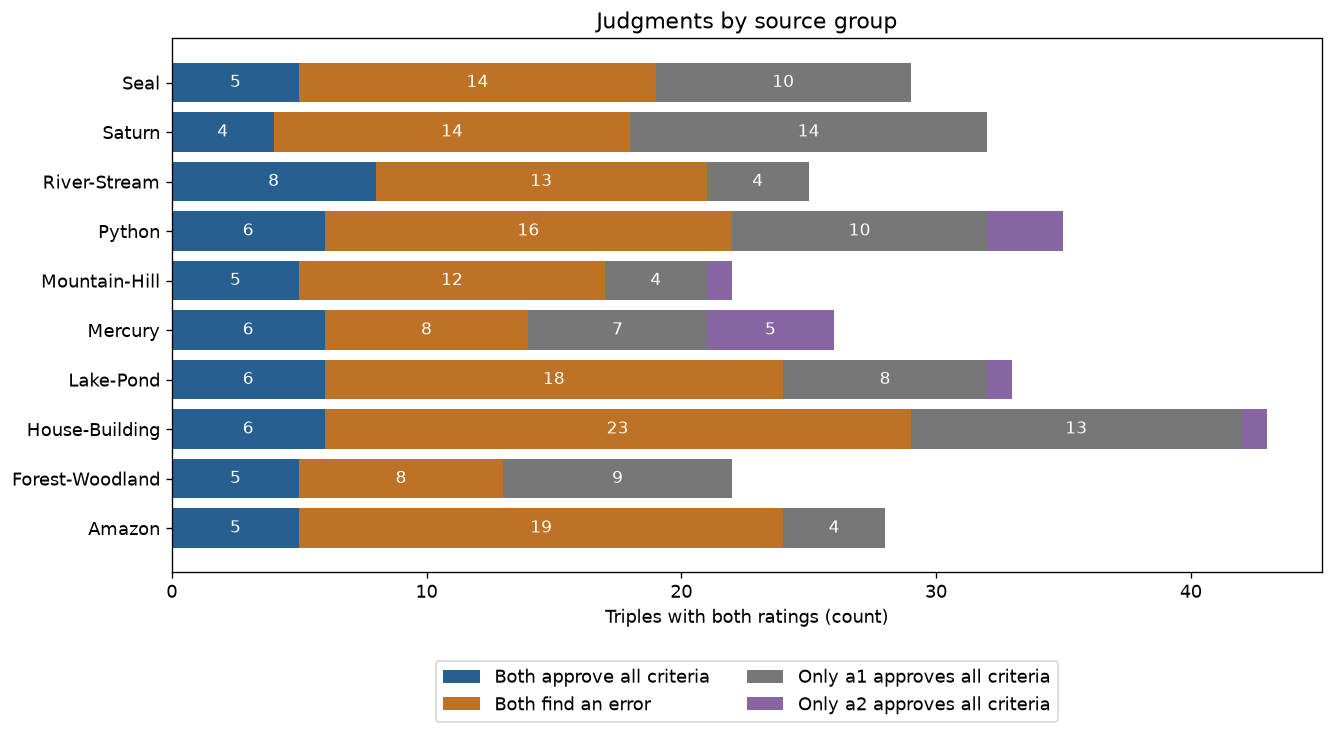

**Answer:** observed agreement is highest in Amazon (85.7%, 28 relationships) and lowest in Mercury (53.8%, 26 relationships). High agreement does not mean frequent approval.

In [6]:
groups=whole.groupby('Identifier')[list(outcomes)].sum()
stacked(groups,list(outcomes),list(outcomes.values()),'Judgments by source group')
groups['total']=groups.sum(axis=1)
groups['acordo']=100*(groups.both_correct+groups.both_incorrect)/groups.total
top=groups.acordo.idxmax(); low=groups.acordo.idxmin()
display(Markdown(f"**Answer:** observed agreement is highest in {top} ({groups.loc[top,'acordo']:.1f}%, {int(groups.loc[top,'total'])} relationships) and lowest in {low} ({groups.loc[low,'acordo']:.1f}%, {int(groups.loc[low,'total'])} relationships). High agreement does not mean frequent approval."))

## 6. How similar are the final graphs? What is Jaccard?

**Jaccard measures how much two sets overlap.** Here, the sets contain the triples in a1 and a2 `rdf_final`, rather than their True/False ratings.

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|}=\frac{\text{shared triples}}{\text{shared triples + only a1 + only a2}}$$

- **Intersection:** triples present in both graphs.
- **Union:** all distinct triples present in either graph. A shared triple is counted once.
- **0%:** no overlap. **100%:** identical nonempty sets. If both sets are empty, this analysis reports an undefined value.

**Small example:** a1 has `{t1, t2, t3}` and a2 has `{t2, t3, t4}`. They share 2 triples and have 4 distinct triples in total, so Jaccard is **2 / 4 = 50%**. Dividing by 6 would count the shared triples twice.

**When to use it:** compare the content of two graphs and see how much their final solutions coincide. This is exact RDF-term matching: changing the subject, predicate, object, or direction changes the triple. Similar wording is not automatically equivalent. Triples are compared within each `Identifier`, so a triple repeated in two groups counts separately.

Labels and relationships are shown separately because matching labels can hide disagreement on relations. Other bars compare sets of entities, predicates, or endpoint pairs; each has its own unit.

**Dice** uses the same shared count with a different formula: $2\times\text{shared}/(|A|+|B|)$. It gives a different scale of overlap, not independent evidence.
**Neither metric tells us which graph is factually correct.** Two graphs can share the same mistake.


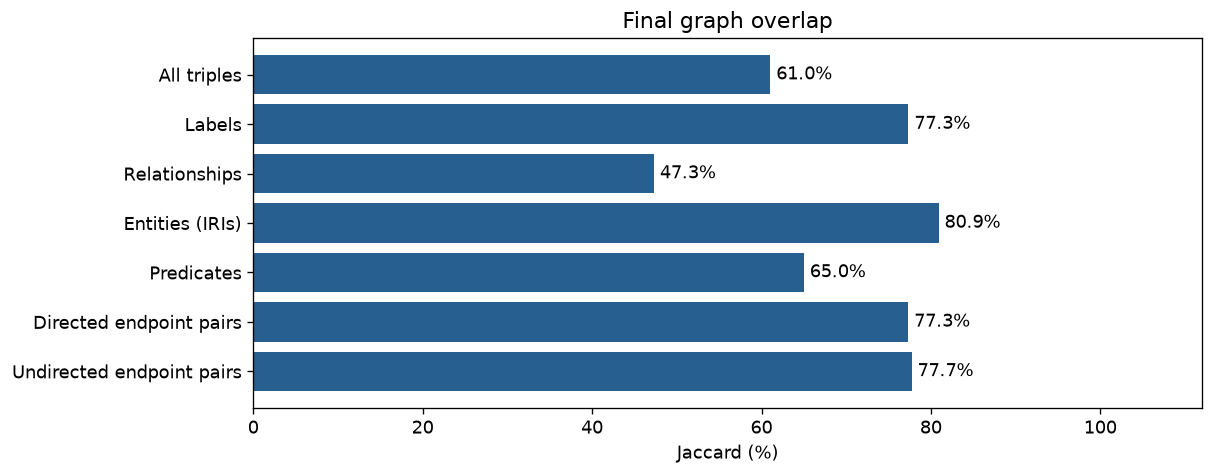

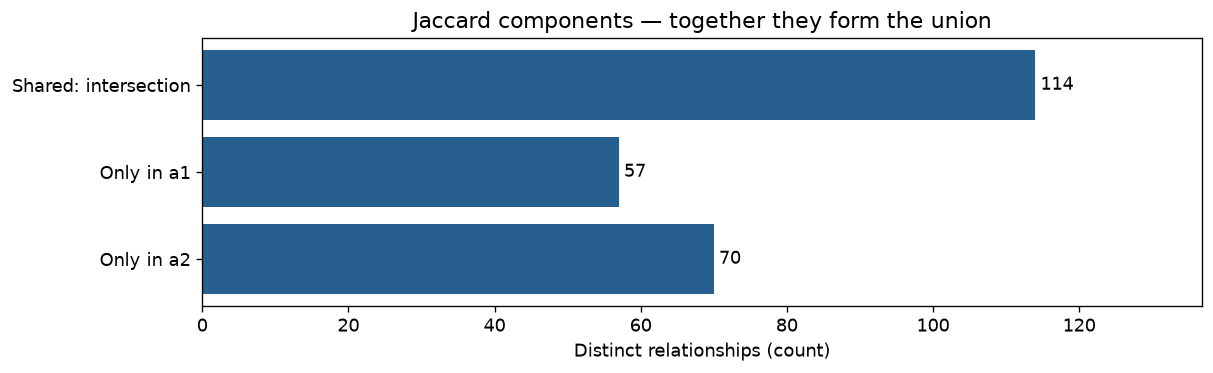

**Answer for these graphs:** a1 has 171 relationships and a2 has 184. They share 114; 57 occur only in a1 and 70 only in a2. The union is 241, so **Jaccard = 114 / 241 = 47.3%**. Dice is 64.2%. These are overlap scores, not accuracy scores.

In [7]:
graphs={r:rdf.load_final_graphs(p,'rdf_final')[0] for r,p in INPUTS.items()}
graph_by_group,graph_totals=rdf.compare_graphs(graphs['a1'],graphs['a2'])

names={'All RDF triples':'All triples','Label triples':'Labels','Relation triples':'Relationships',
       'Endpoint entity IRIs':'Entities (IRIs)','Predicates':'Predicates',
       'Directed endpoint pairs':'Directed endpoint pairs','Undirected endpoint pairs':'Undirected endpoint pairs'}
bars(graph_totals.dimension.map(lambda x:names.get(x,x)),graph_totals.jaccard_pct,
     'Final graph overlap','Jaccard (%)',True)
r=graph_totals.set_index('dimension').loc['Relation triples']
bars(['Shared: intersection','Only in a1','Only in a2'], [r.shared,r.only_a1,r.only_a2], 'Jaccard components — together they form the union', 'Distinct relationships (count)')
display(Markdown(f"**Answer for these graphs:** a1 has {int(r.a1)} relationships and a2 has {int(r.a2)}. They share {int(r.shared)}; {int(r.only_a1)} occur only in a1 and {int(r.only_a2)} only in a2. The union is {int(r.shared+r.only_a1+r.only_a2)}, so **Jaccard = {int(r.shared)} / {int(r.shared+r.only_a1+r.only_a2)} = {r.jaccard_pct:.1f}%**. Dice is {r.dice_pct:.1f}%. These are overlap scores, not accuracy scores."))

## 7. How much do the graphs overlap within each Identifier?

Each row compares the a1 and a2 **relationship triples for the same Identifier**. Label triples are excluded.

**Jaccard for a group = shared relationships / distinct relationships in either graph of that group.**
The chart shows the percentage; the table shows the counts used to calculate it. A high value means similar graph content, not verified correctness.

The overall score above divides the sum of shared counts by the sum of union counts. It is not a simple average of the group percentages: larger unions contribute more weight.


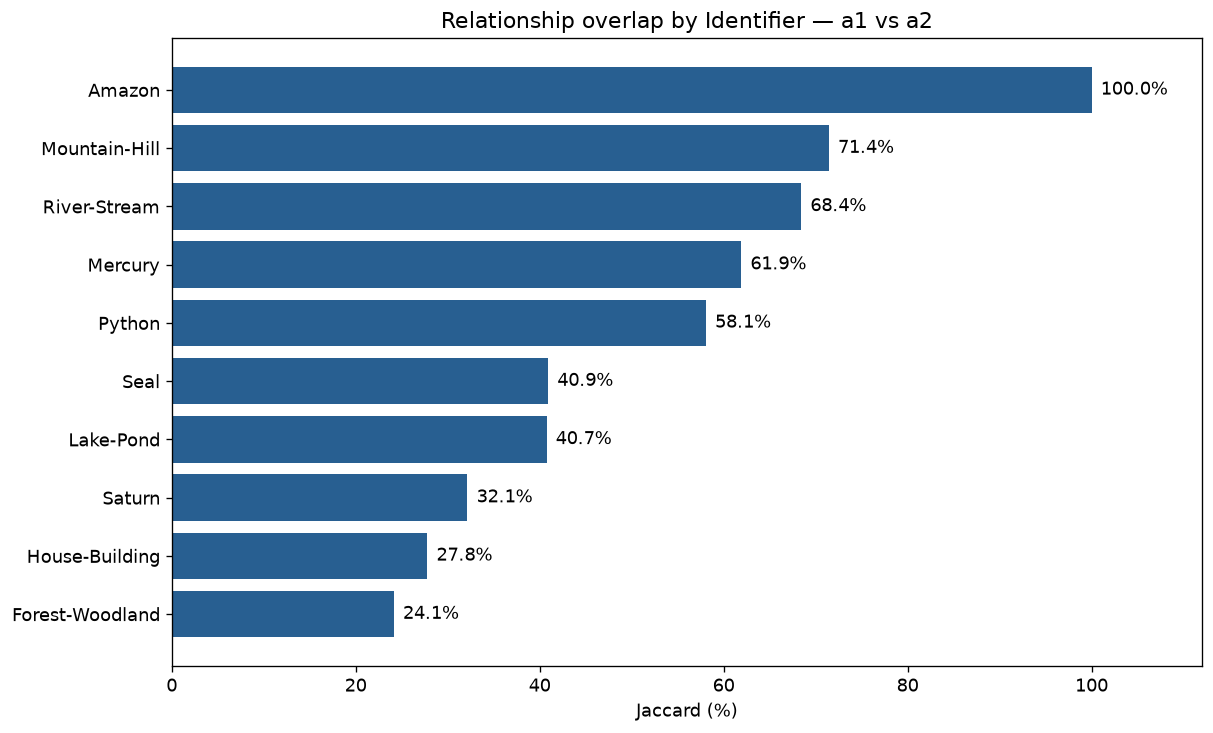

Identifier,a1 relationships,a2 relationships,Shared,Only a1,Only a2,Union,Jaccard (%)
Amazon,14,14,14,0,0,14,100.000
Mountain-Hill,12,12,10,2,2,14,71.429
River-Stream,15,17,13,2,4,19,68.421
Mercury,15,19,13,2,6,21,61.905
Python,25,24,18,7,6,31,58.065
Seal,15,16,9,6,7,22,40.909
Lake-Pond,16,22,11,5,11,27,40.741
Saturn,19,18,9,10,9,28,32.143
House-Building,23,23,10,13,13,36,27.778
Forest-Woodland,17,19,7,10,12,29,24.138


**Answer:** the highest observed overlap is Amazon: 14 shared / 14 distinct relationships = **100.0%**. The lowest is Forest-Woodland: 7 / 29 = **24.1%**. Use the counts to judge the size of each comparison; these scores do not identify the correct graph.

In [8]:
jaccard_by_identifier = graph_by_group.loc[
    graph_by_group.dimension == 'Relation triples',
    ['Identifier', 'a1', 'a2', 'shared', 'only_a1', 'only_a2', 'jaccard_pct']
].copy()
jaccard_by_identifier['union'] = (
    jaccard_by_identifier.shared + jaccard_by_identifier.only_a1 + jaccard_by_identifier.only_a2
)
jaccard_by_identifier = jaccard_by_identifier.sort_values(
    ['jaccard_pct', 'Identifier'], ascending=[False, True], na_position='last'
).reset_index(drop=True)

# Independently verify each reported count against the actual RDF sets.
for row in jaccard_by_identifier.itertuples():
    left = rdf.relation_set(graphs['a1'][row.Identifier])
    right = rdf.relation_set(graphs['a2'][row.Identifier])
    assert row.shared == len(left & right)
    assert row.union == len(left | right)
    expected = 100 * len(left & right) / len(left | right) if left | right else np.nan
    assert np.isclose(row.jaccard_pct, expected, equal_nan=True)

fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
positions = np.arange(len(jaccard_by_identifier))
for i, row in enumerate(jaccard_by_identifier.itertuples()):
    if np.isfinite(row.jaccard_pct):
        ax.barh(i, row.jaccard_pct, color=COLORS[0])
        ax.text(row.jaccard_pct + 1, i, f'{row.jaccard_pct:.1f}%', va='center')
    else:
        ax.text(1, i, 'undefined (empty union)', va='center')
ax.set(yticks=positions, yticklabels=jaccard_by_identifier.Identifier,
       xlim=(0, 112), xlabel='Jaccard (%)',
       title='Relationship overlap by Identifier — a1 vs a2')
ax.invert_yaxis()
plt.show()

table(jaccard_by_identifier[
    ['Identifier', 'a1', 'a2', 'shared', 'only_a1', 'only_a2', 'union', 'jaccard_pct']
].rename(columns={
    'a1': 'a1 relationships', 'a2': 'a2 relationships', 'shared': 'Shared',
    'only_a1': 'Only a1', 'only_a2': 'Only a2', 'union': 'Union', 'jaccard_pct': 'Jaccard (%)'
}))

defined = jaccard_by_identifier.dropna(subset=['jaccard_pct'])
if not defined.empty:
    highest, lowest = defined.iloc[0], defined.iloc[-1]
    display(Markdown(
        f"**Answer:** the highest observed overlap is {highest.Identifier}: "
        f"{int(highest.shared)} shared / {int(highest['union'])} distinct relationships "
        f"= **{highest.jaccard_pct:.1f}%**. The lowest is {lowest.Identifier}: "
        f"{int(lowest.shared)} / {int(lowest['union'])} = **{lowest.jaccard_pct:.1f}%**. "
        "Use the counts to judge the size of each comparison; these scores do not identify the correct graph."
    ))
relation_total = graph_totals.set_index('dimension').loc['Relation triples']
assert jaccard_by_identifier.shared.sum() == relation_total.shared
pooled_union = jaccard_by_identifier['union'].sum()
pooled_jaccard = 100 * jaccard_by_identifier.shared.sum() / pooled_union if pooled_union else np.nan
assert np.isclose(pooled_jaccard, relation_total.jaccard_pct, equal_nan=True)


## How to use these results

- Use criterion counts to see **what both raters approved or rejected**.
- Read **observed agreement, kappa, pi, and coverage together** to assess judgment consistency.
- Use **Jaccard** to compare final graph content, not factual accuracy.
- Open [Disagreements.ipynb](Disagreements.ipynb) to compare proposed solutions. Agreement on an error does not finish the review.

In [9]:
assert all(review.file_sha256(p)==hashes[r] for r,p in INPUTS.items())
assert int(counts.sum())==len(whole)
display(Markdown("**Checks passed:** counts reconcile and source workbooks are unchanged."))

**Checks passed:** counts reconcile and source workbooks are unchanged.